# AI 221 Machine Exercise 1
## Problem 1 - Energy Efficiency in Buildings
#### by Quiel Andrew I. Quiwa and Joel Paolo C. Salvador

In this project, we will be analyzing a dataset containing 768 samples of simulated buildings with 8 attributes (X1 to X8) and 2 targets (Y1 and Y2). The targets and attributes are representative of the following:

X1 Relative Compactness \
X2 Surface Area \
X3 Wall Area \
X4 Roof Area \
X5 Overall Height \
X6 Orientation \
X7 Glazing Area \
X8 Glazing Area Distribution \
Y1 Heating Load \
Y2 Cooling Load

We will predict the heating load Y1 and provide insights on the energy consumption of the sample building simulations.

In [1]:
# Import pandas to read excel file and utilize its dataframe function
# Import numpy for mathematical computations
# Import matplotlib to plot results
# Import sklearn to use train test split function

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

In [2]:
# Read the excel file using pandas and store it in a dataframe

df = pd.read_excel("ENB2012_data.xlsx")
df.describe()


,X1,X2,X3,X4,X5,X6,X7,X8,Y1,Y2
count,768.000000,768.000000,768.000000,768.000000,768.00000,768.000000,768.000000,768.00000,768.000000,768.000000
mean,0.764167,671.708333,318.500000,176.604167,5.25000,3.500000,0.234375,2.81250,22.307195,24.587760
std,0.105777,88.086116,43.626481,45.165950,1.75114,1.118763,0.133221,1.55096,10.090204,9.513306
min,0.620000,514.500000,245.000000,110.250000,3.50000,2.000000,0.000000,0.00000,6.010000,10.900000
25%,0.682500,606.375000,294.000000,140.875000,3.50000,2.750000,0.100000,1.75000,12.992500,15.620000
50%,0.750000,673.750000,318.500000,183.750000,5.25000,3.500000,0.250000,3.00000,18.950000,22.080000
75%,0.830000,741.125000,343.000000,220.500000,7.00000,4.250000,0.400000,4.00000,31.667500,33.132500
max,0.980000,808.500000,416.500000,220.500000,7.00000,5.000000,0.400000,5.00000,43.100000,48.030000


In [3]:
# Additional check to ensure the dataframe was loaded correctly

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 10 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   X1      768 non-null    float64
 1   X2      768 non-null    float64
 2   X3      768 non-null    float64
 3   X4      768 non-null    float64
 4   X5      768 non-null    float64
 5   X6      768 non-null    int64  
 6   X7      768 non-null    float64
 7   X8      768 non-null    int64  
 8   Y1      768 non-null    float64
 9   Y2      768 non-null    float64
dtypes: float64(8), int64(2)
memory usage: 60.1 KB


### Train/Test/Validation Split

In [4]:
# Heating Load Y1 will be used for prediction

X = df[df.columns[0:8]]
y = df[df.columns[8]]

# Split the data into 60% training and 40% temp (validation + test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.4, random_state=42)

# Split temp (validation and test) sets equally (20% each of original data)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, random_state=42)

### Pipeline: Standard Scaler and Linear Ridge Regression
10 choices of regularization will be tested in the pipeline to find the best choice that gives the highest accuracy on the validation data

In [5]:
# import sklearn modules to implement Pipeline, StandardScaler, and Ridge classes + metrics functions

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error

# Regularization Options
alphas = [0.0001, 0.001, 0.01, 0.1, 0.5, 1, 10, 50, 100, 1000]

#Store metric results for each alpha in an empty list
rows = []

# Loop through each alpha, train the model, and evaluate on training and validation sets
for a in alphas:

    # Pipeline to standardize features and apply Ridge regression with current alpha
    model = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=a))
    ])

    # Train the model on the training data
    model.fit(X_train, y_train)

    # Predict on training and validation sets
    pred_train = model.predict(X_train)
    pred_val = model.predict(X_val)

    # Store the R^2 and RMSE for both training and validation sets in the rows list
    rows.append({
        "alpha": a,
        # Show how well the model fits the training data (overfitting if too high)
        "train_r2": r2_score(y_train, pred_train),
        # Show how well the model generalizes to unseen data (validation set) (higher is better)
        "val_r2": r2_score(y_val, pred_val),
        "train_rmse": np.sqrt(mean_squared_error(y_train, pred_train)),
        "val_rmse": np.sqrt(mean_squared_error(y_val, pred_val)),
    })

# Convert the list of dictionaries to a DataFrame for better visualization and analysis
results = pd.DataFrame(rows).sort_values("val_r2", ascending=False)
display(results)

# identify the best alpha from the first row of the sorted results DataFrame
best_alpha = results.iloc[0]["alpha"]
print("Best alpha:", best_alpha)


,alpha,train_r2,val_r2,train_rmse,val_rmse
0,0.0001,0.918186,0.905028,2.871181,3.184543
1,0.0010,0.918186,0.905027,2.871181,3.184563
2,0.0100,0.918186,0.905014,2.871182,3.184770
3,0.1000,0.918182,0.904890,2.871239,3.186847
4,0.5000,0.918123,0.904343,2.872275,3.195995
5,1.0000,0.917998,0.903689,2.874476,3.206909
6,10.0000,0.914597,0.895065,2.933469,3.347414
7,50.0000,0.900812,0.874562,3.161364,3.659854
8,100.0000,0.888892,0.860435,3.345938,3.860444
9,1000.0000,0.692523,0.664764,5.566114,5.983067


Best alpha: 0.0001


### Observations
Running the pipeline across several values of alpha from 0.0001 to 1000 showed decreasing values of R^2 and increasing values of RMS error for both the training and validation sets.

Although the performances from 0.0001 to 50 are very close and well above 90% R^2, using alpha values 100 and 1000 showed sharp degradation of performance or underfitting.

For this model, we recommend choosing a small regularization value.

### Using the best alpha, rebuild the pieline and make one final evaluation on the test data

In [6]:
# Rebuild the pipeline using the best alpha value for the test data

best_model = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_alpha))
])

# Train the best model on the training data
best_model.fit(X_train, y_train)

# Train the best model on the entire training set (train + validation + test)
train_pred = best_model.predict(X_train)
val_pred = best_model.predict(X_val)
test_pred = best_model.predict(X_test)

# Compute final metrics for train/validation/test
train_r2 = r2_score(y_train, train_pred)
val_r2 = r2_score(y_val, val_pred)
test_r2 = r2_score(y_test, test_pred)

train_rmse = np.sqrt(mean_squared_error(y_train, train_pred))
val_rmse = np.sqrt(mean_squared_error(y_val, val_pred))
test_rmse = np.sqrt(mean_squared_error(y_test, test_pred))

train_mae = mean_absolute_error(y_train, train_pred)
val_mae = mean_absolute_error(y_val, val_pred)
test_mae = mean_absolute_error(y_test, test_pred)

# Print final performance block requested in the assignment
print(f"\nFinal evaluation for target = Y1")
print(f"Train -> R^2: {train_r2:.4f}, RMSE: {train_rmse:.4f}, MAE: {train_mae:.4f}")
print(f"Val   -> R^2: {val_r2:.4f}, RMSE: {val_rmse:.4f}, MAE: {val_mae:.4f}")
print(f"Test  -> R^2: {test_r2:.4f}, RMSE: {test_rmse:.4f}, MAE: {test_mae:.4f}")

# Access the Ridge regression step from the best model pipeline to inspect coefficients or other attributes
ridge = best_model.named_steps["ridge"]
# Print model intercept
print("\nIntercept:", ridge.intercept_)

# Build coefficient table and sort by absolute magnitude
coef_table = pd.DataFrame({
    "feature": X.columns,
    "coefficient": ridge.coef_,
    "abs_coefficient": np.abs(ridge.coef_)
}).sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

# Display coefficients table (includes ranking)
print("\nBest model coefficients (sorted by |coefficient|):")
display(coef_table)





Final evaluation for target = Y1
Train -> R^2: 0.9182, RMSE: 2.8712, MAE: 2.0298
Val   -> R^2: 0.9050, RMSE: 3.1845, MAE: 2.2591
Test  -> R^2: 0.9196, RMSE: 2.8111, MAE: 2.0430

Intercept: 22.079978260869552

Best model coefficients (sorted by |coefficient|):


,feature,coefficient,abs_coefficient
0,X5,7.278819,7.278819
1,X1,-6.307736,6.307736
2,X4,-3.741559,3.741559
3,X2,-3.447142,3.447142
4,X7,2.701363,2.701363
5,X3,0.837847,0.837847
6,X8,0.376469,0.376469
7,X6,-0.020008,0.020008


### Part B: Top 5 Features + Repeat using only the Top 5 features
The top 5 features based on the absolute value coefficient are X5, X1, X4, X2, and X7. 

This means that the following features of the building were most relevant in predicting the heating load of buildings:

1. Overall Height (+7.278819)
2. Relative Compactness (-6.307736)
3. Roof Area (-3.741559)
4. Surface Area (-3.447142)
5. Glazing Area (2.701363)

Note that we used the absolute value of the coefficients because we're looking at the general influence of the attribute on the target whether positive or negative. It's important to emphasize that the sign only shows direction, while the magnitude shows importance. 

For example, the positive value of overall height shows that as the building height increases, the predicted heating load also increases. On the other hand, for negative coefficients values like relative compactness, roof area, and surface area, increasing their values lead to lower values of the predicted heating load.

This also means that the wall area, glazing area distribution, and orientation of the building might not be too relevant in the model. We will test this hypothesis below by repeating the model using only the top 5 features.

In [7]:
# Select top 5 features from part (a) based on absolute coefficient magnitude
top5_features = coef_table["feature"].head(5).tolist()
# Print selected top 5 feature names
print("Top 5 features from part (a):", top5_features)

Top 5 features from part (a): ['X5', 'X1', 'X4', 'X2', 'X7']


In [8]:
# Create reduced feature matrix with only top 5 features
X_top5 = df[top5_features]
# Keep same target
y_top5 = df[df.columns[8]]


In [9]:
# Repeat same 60/20/20 split on reduced feature set
X_train_5, X_temp_5, y_train_5, y_temp_5 = train_test_split(
    X_top5, y_top5, test_size=0.4, random_state=42
)
X_val_5, X_test_5, y_val_5, y_test_5 = train_test_split(
    X_temp_5, y_temp_5, test_size=0.5, random_state=42
)

# Store alpha tuning results for top-5 model
rows_5 = []

# Tune same alpha list for reduced model
for a in alphas:
    # Build pipeline for current alpha
    model_5 = Pipeline([
        ("scaler", StandardScaler()),
        ("ridge", Ridge(alpha=a))
    ])

    # Fit on reduced training data
    model_5.fit(X_train_5, y_train_5)

    # Predict on reduced train and validation data
    pred_train_5 = model_5.predict(X_train_5)
    pred_val_5 = model_5.predict(X_val_5)

    # Save metrics for this alpha
    rows_5.append({
        "alpha": a,
        "train_r2": r2_score(y_train_5, pred_train_5),
        "val_r2": r2_score(y_val_5, pred_val_5),
        "train_rmse": np.sqrt(mean_squared_error(y_train_5, pred_train_5)),
        "val_rmse": np.sqrt(mean_squared_error(y_val_5, pred_val_5)),
        "train_mae": mean_absolute_error(y_train_5, pred_train_5),
        "val_mae": mean_absolute_error(y_val_5, pred_val_5),
    })

# Convert and sort reduced-model tuning table
results_5 = pd.DataFrame(rows_5).sort_values("val_r2", ascending=False).reset_index(drop=True)
# Display reduced-model tuning results
display(results_5)

# Pick best alpha for top-5 model
best_alpha_5 = float(results_5.iloc[0]["alpha"])
# Print best alpha for reduced model
print("Best alpha (top-5 model):", best_alpha_5)

,alpha,train_r2,val_r2,train_rmse,val_rmse,train_mae,val_mae
0,0.0001,0.916828,0.904852,2.894899,3.187485,2.019946,2.250951
1,0.0010,0.916828,0.904851,2.894899,3.187500,2.019939,2.250956
2,0.0100,0.916828,0.904842,2.894900,3.187650,2.019859,2.250999
3,0.1000,0.916826,0.904753,2.894941,3.189145,2.019156,2.251380
4,0.5000,0.916785,0.904375,2.895655,3.195471,2.018558,2.252813
5,1.0000,0.916703,0.903949,2.897084,3.202578,2.019310,2.255828
6,10.0000,0.914676,0.899059,2.932112,3.283086,2.035976,2.298691
7,50.0000,0.895857,0.876399,3.239378,3.632946,2.311030,2.545516
8,100.0000,0.866757,0.845992,3.664109,4.055272,2.728063,2.933020
9,1000.0000,0.616713,0.597432,6.214524,6.556445,4.882115,5.198262


Best alpha (top-5 model): 0.0001


### Initial Observations

Similar to Part A, alpha = 0.0001 still performed best with only the top 5 features. Off-hand, we can observe that the R^2 values are slightly lower and the RMSE values are slightly higher. Perhaps, depending on the type of insight we want to gain, these very small percentage differences might be considered negligible. On the other hand, for larger datasets, reducing the number of features could also improve the computational load and make the model run faster.

In [10]:
# Fit final reduced model with best alpha
best_model_5 = Pipeline([
    ("scaler", StandardScaler()),
    ("ridge", Ridge(alpha=best_alpha_5))
])
best_model_5.fit(X_train_5, y_train_5)

# Predict on reduced train/val/test splits
train_pred_5 = best_model_5.predict(X_train_5)
val_pred_5 = best_model_5.predict(X_val_5)
test_pred_5 = best_model_5.predict(X_test_5)

# Compute reduced-model final metrics
train_r2_5 = r2_score(y_train_5, train_pred_5)
val_r2_5 = r2_score(y_val_5, val_pred_5)
test_r2_5 = r2_score(y_test_5, test_pred_5)

train_rmse_5 = np.sqrt(mean_squared_error(y_train_5, train_pred_5))
val_rmse_5 = np.sqrt(mean_squared_error(y_val_5, val_pred_5))
test_rmse_5 = np.sqrt(mean_squared_error(y_test_5, test_pred_5))

train_mae_5 = mean_absolute_error(y_train_5, train_pred_5)
val_mae_5 = mean_absolute_error(y_val_5, val_pred_5)
test_mae_5 = mean_absolute_error(y_test_5, test_pred_5)

# Print final reduced-model evaluation
print(f"\nFinal evaluation for top-5 model (target = Y1)")
print(f"Train -> R^2: {train_r2_5:.4f}, RMSE: {train_rmse_5:.4f}, MAE: {train_mae_5:.4f}")
print(f"Val   -> R^2: {val_r2_5:.4f}, RMSE: {val_rmse_5:.4f}, MAE: {val_mae_5:.4f}")
print(f"Test  -> R^2: {test_r2_5:.4f}, RMSE: {test_rmse_5:.4f}, MAE: {test_mae_5:.4f}")

# Extract reduced-model coefficients/intercept
ridge_5 = best_model_5.named_steps["ridge"]
# Print reduced-model intercept
print("\nTop-5 model intercept:", ridge_5.intercept_)

# Build reduced-model coefficient table
coef_table_5 = pd.DataFrame({
    "feature": X_top5.columns,
    "coefficient": ridge_5.coef_,
    "abs_coefficient": np.abs(ridge_5.coef_)
}).sort_values("abs_coefficient", ascending=False).reset_index(drop=True)

# Display reduced-model coefficients
print("\nTop-5 model coefficients:")
display(coef_table_5)

# Build compact comparison table for part (a) vs part (b)
comparison = pd.DataFrame([
    {
        "model": "All 8 features",
        "best_alpha": best_alpha,
        "train_r2": train_r2,
        "val_r2": val_r2,
        "test_r2": test_r2,
        "train_rmse": train_rmse,
        "val_rmse": val_rmse,
        "test_rmse": test_rmse
    },
    {
        "model": "Top 5 features",
        "best_alpha": best_alpha_5,
        "train_r2": train_r2_5,
        "val_r2": val_r2_5,
        "test_r2": test_r2_5,
        "train_rmse": train_rmse_5,
        "val_rmse": val_rmse_5,
        "test_rmse": test_rmse_5
    }
])

# Show final side-by-side results for report
print("\nComparison of part (a) and part (b):")
display(comparison)



Final evaluation for top-5 model (target = Y1)
Train -> R^2: 0.9168, RMSE: 2.8949, MAE: 2.0199
Val   -> R^2: 0.9049, RMSE: 3.1875, MAE: 2.2510
Test  -> R^2: 0.9195, RMSE: 2.8130, MAE: 1.9992

Top-5 model intercept: 22.07997826086955

Top-5 model coefficients:


,feature,coefficient,abs_coefficient
0,X5,7.275404,7.275404
1,X1,-6.297022,6.297022
2,X4,-5.465579,5.465579
3,X7,2.771596,2.771596
4,X2,-1.768164,1.768164



Comparison of part (a) and part (b):


,model,best_alpha,train_r2,val_r2,test_r2,train_rmse,val_rmse,test_rmse
0,All 8 features,0.0001,0.918186,0.905028,0.919587,2.871181,3.184543,2.811065
1,Top 5 features,0.0001,0.916828,0.904852,0.919477,2.894899,3.187485,2.812983


### Additional Observations
Comparing the results of part A and B show very little differences, confirming our hypothesis that the wall area, glazing area distribution, and orientation of the building might not be too relevant in the model.

To help with the interpretation of the model, we will also plot the results below:

### Additional Work: Plot

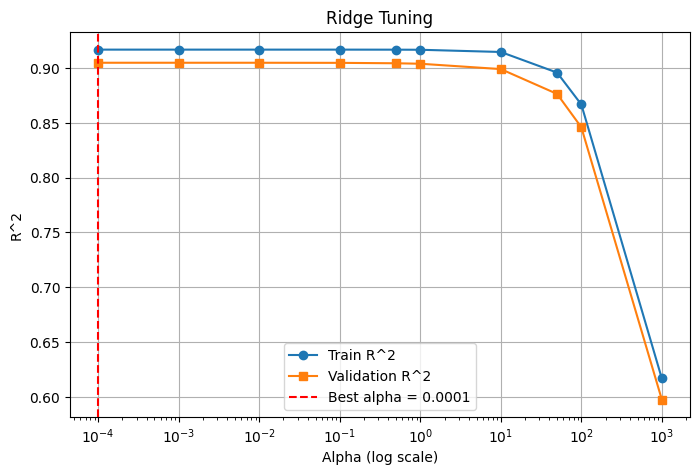

In [ ]:
# Plot validation and training R^2 vs alpha (log-scale x-axis)
plt.figure(figsize=(8, 5))

# Use semilogx to plot with log-scale x-axis for better visualization of alpha effects
plt.semilogx(results_5["alpha"], results_5["train_r2"], marker="o", label="Train R^2")
plt.semilogx(results_5["alpha"], results_5["val_r2"], marker="s", label="Validation R^2")

# We did not include test R^2 in the plot since it is not used for alpha tuning and would be misleading to show on the same plot (test set is only for final evaluation, not tuning)


# Mark the best alpha chosen by validation R^2
plt.axvline(best_alpha, color="red", linestyle="--", label=f"Best alpha = {best_alpha:g}")

plt.title("Ridge Tuning")
plt.xlabel("Alpha (log scale)")
plt.ylabel("R^2")
plt.grid()
plt.legend()
plt.show()


### Ridge Tuning Observation
As observed previously, the R^2 values decrease as alpha increases, with a sharp dip in performance occuring at alpha = 100. We can also see that there is minimal overfitting because the training and validation scores are very close across all values of alpha. This means that the model generalizes well with respect to unseen data and it's not just memorizing the training data.

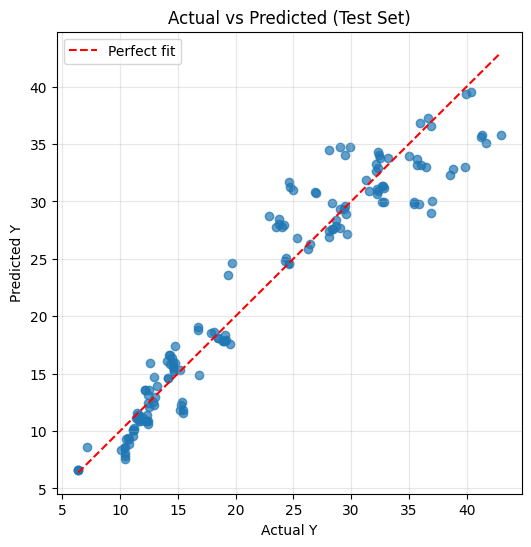

In [37]:
# Predictions on test set
y_test_pred = best_model.predict(X_test)

plt.figure(figsize=(6, 6))
plt.scatter(y_test, y_test_pred, alpha=0.7)
mn = min(y_test.min(), y_test_pred.min())
mx = max(y_test.max(), y_test_pred.max())
plt.plot([mn, mx], [mn, mx], "r--", label="Perfect fit")
plt.xlabel("Actual Y")
plt.ylabel("Predicted Y")
plt.title("Actual vs Predicted (Test Set)")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Insights

### Plot Observations
Based on the actual vs. predicted plot on the test set, we can see that the model generally close to the diagonal dashed line. This means that the model predictions are generally accurate and captures the overall relationship between features and heating load.

However, if we look at the values of heating loads above 30, many predictions fall below the red line. This shows that the model underestimates high heating loads. This might be caused by the Ridge regularization model shrinking coefficients and reducing extreme predictions. Ridge regression penalizes large coefficients so the model may produce less extreme predictions and slightly underestimate very high heating loads.

### Ridge Regression Tuning
Summarizing the observations mentioned throughout the notebook:
1. As alpha increases, both training and validation R^2 decrease while RMSE increases.
2. Small alpha values (0.0001–1) produce the best performance.
3. Very large alpha values (100 and 1000) cause significant performance degradation.

As observed in the plot, large alpha values are penalized for their coefficients so the model becomes overly simple and performs poorly. Small alpha values, on the other hand required minimal regularization and maintained low bias.


### On Feature Importance
By ranking coefficients with respect to absolute magnitude, we identified the most influential features to be X5, X1, X4, X2, and X7. 

This means that the following features of the building were most relevant in predicting the heating load of buildings:

1. Overall Height (+7.278819) - Taller buildings tend to require more heating due to larger interior volume.
2. Relative Compactness (-6.307736) - More compact buildings lose less heat, resulting in lower heating demand.
3. Roof Area (-3.741559) and Surface Area (-3.447142) - Larger window areas increase heat transfer, potentially increasing heating demand.
4. Glazing Area (2.701363) - Larger window areas increase heat transfer, potentially increasing heating demand.

Other features like wall area, orientation, and glazing area distribution were found to contribute little to the predictive performance of the model.

### On the Reduced Model
The difference in performance between the 8-feature model and the 5-feature model were very small, indicating that the reduced model is still acceptable for predicting heating load values. For very large datasets, reducing the number of features could result in faster computation or more efficient compute requirements. This experiment helped me understand the importance of feature selection.
